In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import cv2
import json
import numpy as np
from PIL import Image
import os
import glob

# Prepare data

In [2]:
image_paths = glob.glob('./data/*.jpg')
json_paths = [pth.replace('jpg', 'json') for pth in image_paths]
image_paths, json_paths

(['./data/006_IT158412_1.jpg',
  './data/008_IT158764_1.jpg',
  './data/009_IT221893_1.jpg',
  './data/010_IT223741_1.jpg',
  './data/001_IT135673_1.jpg',
  './data/004_IT158286_1.jpg',
  './data/003_IT158279_1.jpg',
  './data/011_IT223788_1.jpg',
  './data/012_IT225004_1.jpg'],
 ['./data/006_IT158412_1.json',
  './data/008_IT158764_1.json',
  './data/009_IT221893_1.json',
  './data/010_IT223741_1.json',
  './data/001_IT135673_1.json',
  './data/004_IT158286_1.json',
  './data/003_IT158279_1.json',
  './data/011_IT223788_1.json',
  './data/012_IT225004_1.json'])

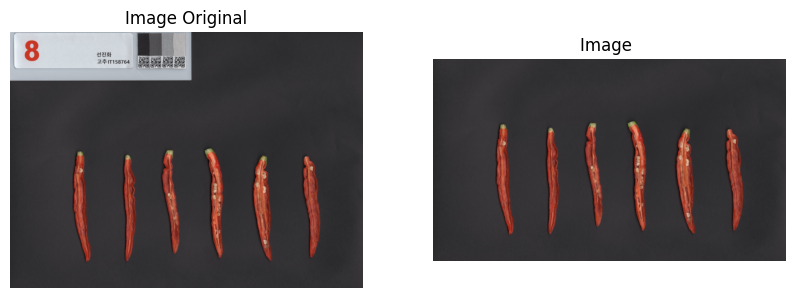

In [3]:
image = cv2.imread(image_paths[1])
image_RGB = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_crop = image_RGB[540:, :, :]

plt.figure(figsize=(10,5))

plt.subplot(1, 2, 1)
plt.imshow(image_RGB)
plt.title("Image Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_crop)
plt.title("Image ")
plt.axis("off")

plt.show()

# Get Bbox

### Detect bbox by threshold

In [4]:
# from segment import SegmentModel
from src.detect import DetectModel

model_detect = DetectModel(model_name='none')
# model_detect.predict(image_paths[0])

Use threshold for detect each chili fruit


In [ ]:
path = image_paths[1]
masks = model_detect.predict(path)
image = cv2.imread(path)
H, W, _ = image.shape

for i, mask in enumerate(masks):
    x, y, w, h = mask
    # print(x,y,w,h)
    img = image[max(0, y-50):min(H,y+h+50), max(0,x-50):min(W,x+w+50)]
    cv2.imwrite(f"runs/detect/predict/output_{i}.jpg", img)
    # cv2.rectangle(image, (x-50, y-50), (x + w +50, y + h+50), (0, 255, 0), 2)

### Detect chili by model YOLO

In [6]:
from src.detect import DetectModel

# model_detete = DetectModel(model_name='yolo', weight_path='./pretrain/yolov7_detect_v1.pt')
# model_detete.predict(image_paths[0])

# Segment for each chili

In [7]:
from src.segment import SegmentModel

model_seg = SegmentModel(weight_path='./pretrain/yolov8_segment_v1.pt', model_name='yolo')

In [ ]:
import glob

img_paths = glob.glob('./runs/detect/predict/*.jpg')
imgs = [Image.open(path) for path in img_paths]
results = model_seg.predict(imgs[0])

r = results[0]  # first image result


0: 640x160 1 seed, 1 placenta, 1 endocarp, 286.1ms
Speed: 6.4ms preprocess, 286.1ms inference, 5.3ms postprocess per image at shape (1, 3, 640, 160)
Results saved to /home/lap15692/Downloads/chili_paper/Applying-Machine-Learning-for-Chili-Pepper-Phenotyping-and-Feature-Extraction-v2/runs/segment/predict


In [24]:
names = r.names
masks = r.masks.data
polygons = r.masks.xy
xyxy = r.boxes.xyxy      # (N,4)
cls  = r.boxes.cls
conf = r.boxes.conf

In [26]:
masks.shape

torch.Size([3, 1203, 272])

# Test pipeline

# Accuracy

# App demo